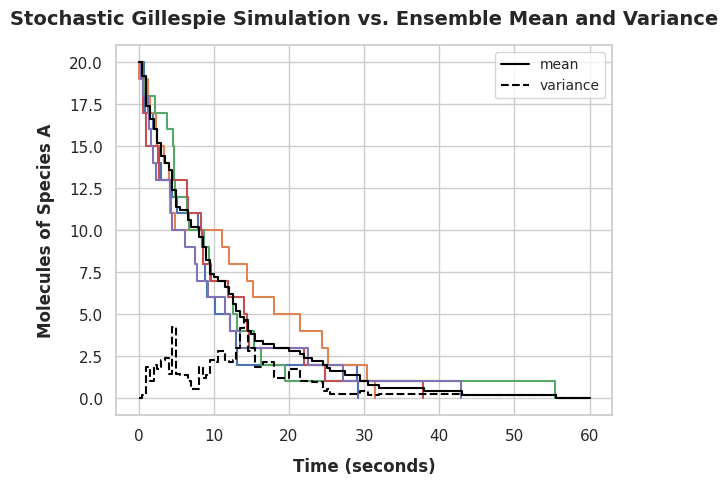

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
import math
import random

t=0 #initial time is taken as 0
t2=0 #initial time is taken as 0
A=20 #initial number of molecules belonging to species A
k=0.1 #sec^-1, rate constant for the reaction A-k->phi
mt=60 #maximum_time
phi=0 #initial number of molecules belonging to species phi
times=[t]
countA=[A]
meantime=np.arange(0,60.001,0.5)
conc=np.zeros((5,121))
dt=0.5
a1=0.0
a0=0.0
tau=0



def degrad(A,a1,k,mt):
 a1=A*k
 a0=a1
 t=0
 t2=0
 j=0
 conc[i,0]=A
 while a0!=0:

  if(t>=mt or t2>=mt):
    break

  r1=random.random()
  tau=(1/a0)*math.log(1/r1)
  t+=tau
  while(t2+dt)<=t:
   j+=1
   t2+=dt
   if j>=conc.shape[1]:
     break
   conc[i,j]=A
  A=A-1
  countA.append(A)
  times.append(t)
  a0 = A * k
 while(t2+dt)<=mt:
  j+=1
  t2+=dt
  if j>=conc.shape[1]:
   break
  conc[i,j]=A
 return countA,times,conc



for i in range(5):
 degrad(A,a1,k,mt)
 countA=np.array(countA)
 times=np.array(times)
 plt.step(times,countA,where='post')

 t=0
 A=20
 k=0.1
 mt=60
 phi=0
 times=[t]
 countA=[A]
 a1=0.0
 a0=0.0
 tau=0
plt.step(meantime,np.mean(conc,axis=0),where='post',label='mean',color='black')
plt.step(meantime,np.var(conc,axis=0),where='post',label='variance',color='black',ls='dashed')
plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Molecules of Species A', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Stochastic Gillespie Simulation vs. Ensemble Mean and Variance', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
plt.show()








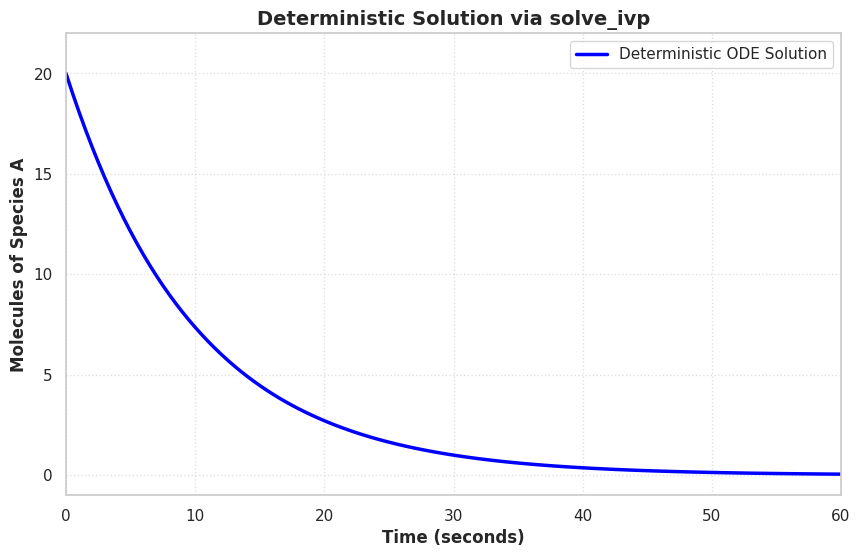

In [ ]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt
import seaborn as sns

def ode_system(t, A, k):
    return -k * A

A_init = [20]
k_val = 0.1
t_span = (0, 60)
t_eval = np.linspace(0, 60, 121)

sol = solve_ivp(ode_system, t_span, A_init, args=(k_val,), t_eval=t_eval)

plt.figure(figsize=(10, 6))
plt.plot(sol.t, sol.y[0], label='Deterministic ODE Solution', color='blue', linewidth=2.5)
plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold')
plt.ylabel('Molecules of Species A', fontsize=12, fontweight='bold')
plt.title('Deterministic Solution via solve_ivp', fontsize=14, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.xlim(t_span)
plt.ylim(-1, A_init[0] + 2)
plt.show()

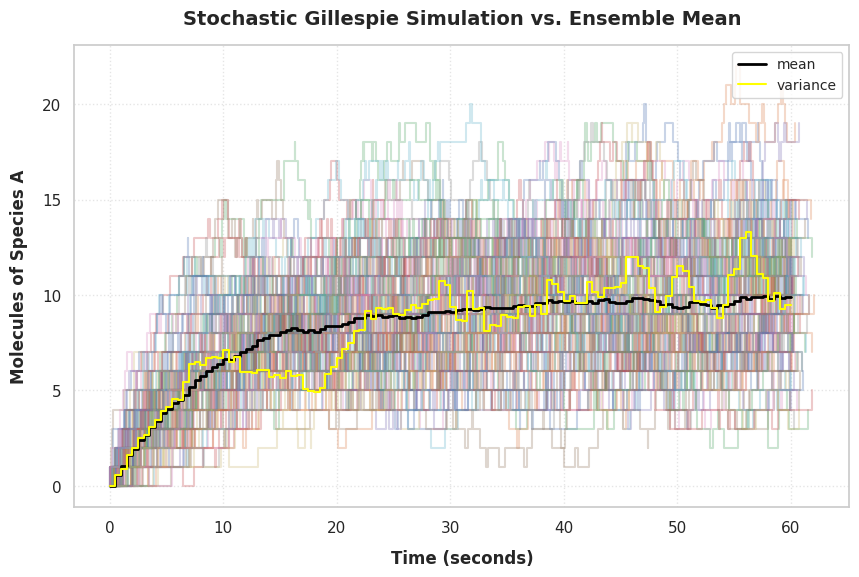

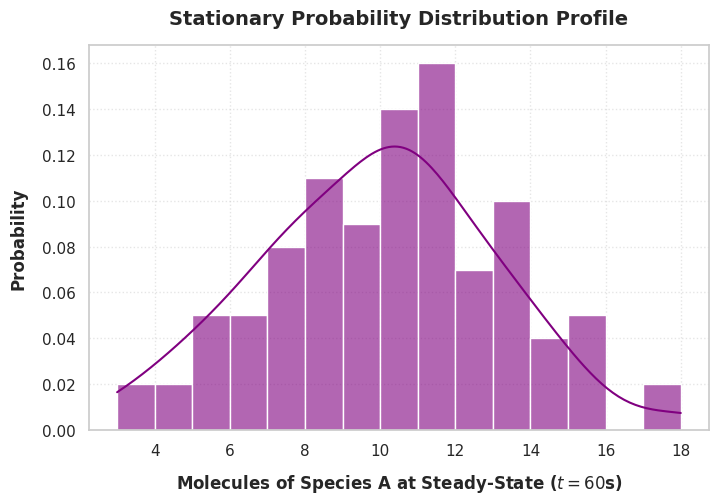

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
import math
import random
import seaborn as sns

t=0
t2=0
A=0
k1=0.1
k2=1
mt=60
phi=0
times=[t]
countA=[A]
meantime=np.arange(0,60.001,0.5)
conc=np.zeros((100,121))
dt=0.5
a1=0.0
a0=0.0
tau=0

def degpro(A,k1,k2,mt):
 a1=A*k1
 a2=k2
 a0=a1+a2
 t=0
 t2=0
 j=0

 conc[i,0]=A
 while True:

  if(t>=mt or t2>=mt):
    break

  r1=random.random()
  tau=(1/a0)*math.log(1/r1)
  t+=tau
  r2=random.random()
  while(t2+dt)<=t:
   j+=1
   t2+=dt
   if j>=conc.shape[1]:
     break
   conc[i,j]=A
  if (r2*a0)<=a1:
   A=A-1
  else:
   A=A+1
  countA.append(A)
  times.append(t)
  a1=A*k1
  a2=k2
  a0 = A*k1+k2
 while(t2+dt)<=mt:
  j+=1
  t2+=dt
  if j>=conc.shape[1]:
   break
  conc[i,j]=A
 return countA,times,conc

plt.figure(1, figsize=(10, 6))

for i in range(100):
 degpro(A,k1,k2,mt)
 countA=np.array(countA)
 times=np.array(times)
 plt.step(times,countA,where='post', alpha=0.3)
 t=0
 A=0
 k1=0.1
 k2=1
 mt=60
 times=[t]
 countA=[A]
 tau=0

plt.step(meantime,np.mean(conc,axis=0),where='post',label='mean',color='black', linewidth=2)
plt.step(meantime,np.var(conc,axis=0),where='post',label='variance',color='yellow', linewidth=1.5)
plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Molecules of Species A', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Stochastic Gillespie Simulation vs. Ensemble Mean', fontsize=14, fontweight='bold', pad=15)
plt.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
plt.grid(True, linestyle=':', alpha=0.5)

plt.figure(2, figsize=(8, 5))

stationary_states=conc[:,-1]
sns.histplot(stationary_states, kde=True, stat="probability", color="purple", bins=15, alpha=0.6)
plt.xlabel('Molecules of Species A at Steady-State ($t = 60$s)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Probability', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Stationary Probability Distribution Profile', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle=':', alpha=0.5)

plt.show()

Text(0, 0.5, 'Molecules')

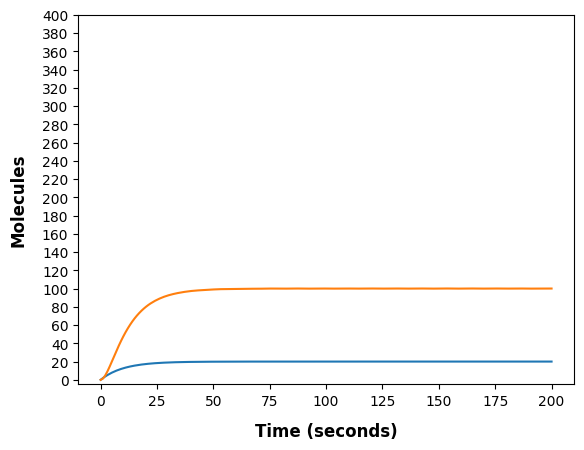

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
import math
import random

def protein(t,space):
 m,p=space
 am=2.0
 bm=0.1
 ap=1.5
 bp=0.3
 dmdt=am-bm*m
 dptdt=ap*m-bp*p
 return [dmdt,dptdt]
t=np.linspace(0,200,200)
y0=[0.01,0.0]
sol=solve_ivp(protein,(t[0],t[-1]),y0,t_eval=t)
plt.plot(t,sol.y[0],label='m')
plt.plot(t,sol.y[1],label='p')
plt.yticks(np.arange(0,401,20))
plt.xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)

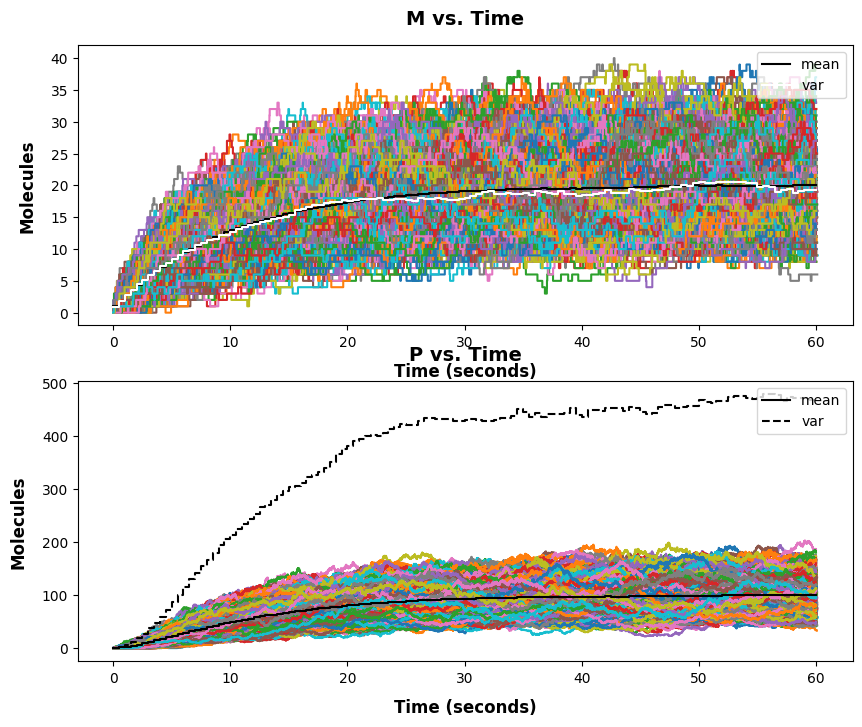

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
import math
import random
meantime=np.arange(0,60.001,0.5)
concm=np.zeros((2000,121))
concp=np.zeros((2000,121))
m=0.0
p=0.01


def pro(ap,bp,am,bm,m,p,i):
 concm[i,0]=m
 concp[i,0]=p
 t=0
 t2=0
 dt=0.5
 mt=60
 j=0
 CM=[m]
 CP=[p]
 times=[t]

 while True:
  if(t>=mt or t2>=mt):
    break
  if j>=concm.shape[1]:
   break
  a1=am
  a2=bm*m
  a3=ap*m
  a4=bp*p
  a0=a1+a2+a3+a4
  r1=random.random()
  tau=(1/a0)*math.log(1/r1)
  t+=tau
  r2=random.random()
  while((t2+dt)<=t):
    j=j+1
    t2+=dt
    if j>=concm.shape[1]:
     break
    concm[i,j]=m
    concp[i,j]=p
  if (r2*a0)<=a1:
   m=m+1
  elif (r2*a0)<=a1+a2 and (r2*a0)>a1:
   m=m-1
  elif (r2*a0)<=a1+a2+a3 and (r2*a0)>a1+a2:
   p=p+1
  else:
   p=p-1
  concm[i,j]=m
  concp[i,j]=p
  CM.append(m)
  CP.append(p)
  times.append(t)

 return CM,CP,concm,concp,times
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

for i in range(2000):
 am=2.0
 bm=0.1
 ap=1.5
 bp=0.3
 CM,CP,concm,concp,times=pro(ap,bp,am,bm,m,p,i)
 concm=np.array(concm)
 concp=np.array(concp)
 times=np.array(times)
 axes[0].step(times,CM,where='post')
 axes[1].step(times,CP,where='post')


mean_m=np.mean(concm,axis=0)
mean_p=np.mean(concp,axis=0)
var_m=np.var(concm,axis=0)
var_p=np.var(concp,axis=0)


axes[0].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_title('M vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[1].set_title('P vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[0].step(meantime,mean_m,where='post',label='mean',color='black')
axes[1].step(meantime,mean_p,where='post',label='mean',color='black')
axes[0].step(meantime,var_m,where='post',label='var',color='white')
axes[1].step(meantime,var_p,where='post',label='var',color='black',ls='dashed')
axes[0].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
axes[1].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')



plt.show()




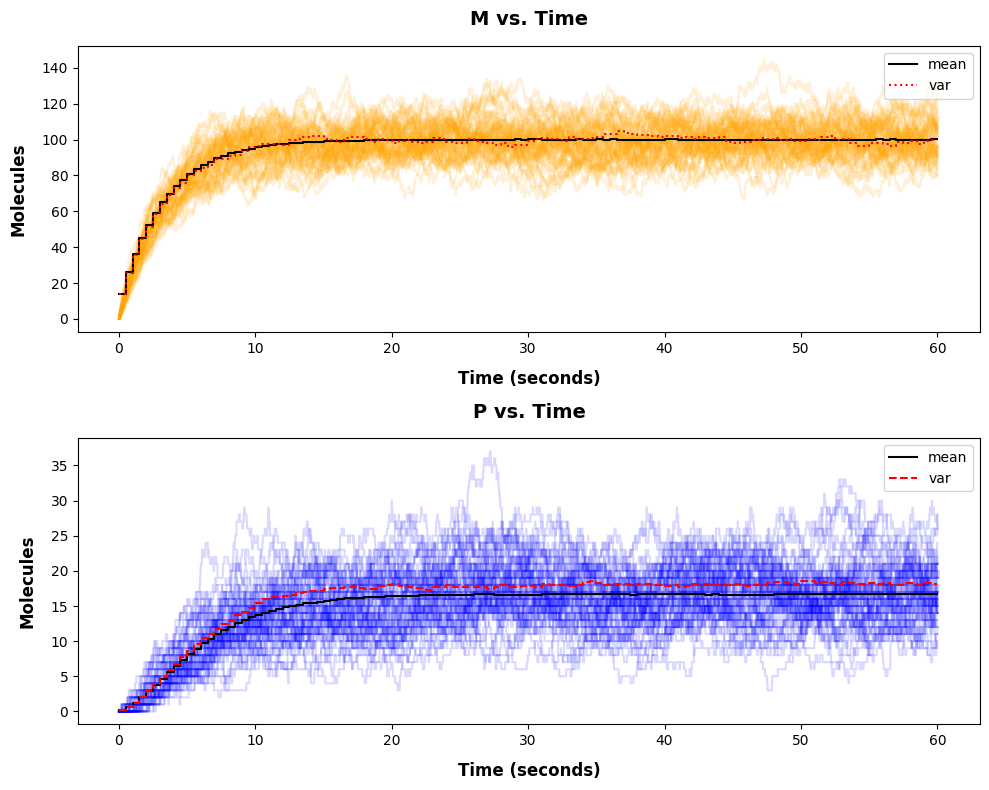

In [ ]:
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import numpy as np
import math
import random
from numba import njit

meantime = np.arange(0, 60.001, 0.5)
concm = np.zeros((10000, 121))
concp = np.zeros((10000, 121))
m = 0.0
p = 0.01

@njit
def pro(ap, bp, am, bm, m, p, i, concm, concp):
    concm[i, 0] = m
    concp[i, 0] = p
    t = 0
    t2 = 0
    dt = 0.5
    mt = 60
    j = 0
    CM = [m]
    CP = [p]
    times = [t]

    while True:
        if t >= mt or t2 >= mt:
            break
        if j >= concm.shape[1]:
            break
        a1 = am
        a2 = bm * m
        a3 = ap * m
        a4 = bp * p
        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            break

        r1 = np.random.random()
        tau = (1 / a0) * math.log(1 / r1)
        t += tau
        r2 = np.random.random()

        while (t2 + dt) <= t:
            j = j + 1
            t2 += dt
            if j >= concm.shape[1]:
                break
            concm[i, j] = m
            concp[i, j] = p

        if (r2 * a0) <= a1:
            m = m + 1
        elif (r2 * a0) <= a1 + a2 and (r2 * a0) > a1:
            m = m - 1
        elif (r2 * a0) <= a1 + a2 + a3 and (r2 * a0) > a1 + a2:
            p = p + 1
        else:
            p = p - 1

        if j >= concm.shape[1]:
            break

        concm[i, j] = m
        concp[i, j] = p
        CM.append(m)
        CP.append(p)
        times.append(t)

    return CM, CP, times

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

for i in range(10000):
    am = 30.0
    bm = 0.3
    ap = 0.05
    bp = 0.3
    CM, CP, times = pro(ap, bp, am, bm, m, p, i, concm, concp)

    if i < 50:
        axes[0].step(times, CM, where='post', alpha=0.15, color='orange')
        axes[1].step(times, CP, where='post', alpha=0.15, color='blue')

mean_m = np.mean(concm, axis=0)
mean_p = np.mean(concp, axis=0)
var_m = np.var(concm, axis=0)
var_p = np.var(concp, axis=0)

axes[0].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_title('M vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[1].set_title('P vs. Time', fontsize=14, fontweight='bold', pad=15)

axes[0].step(meantime, mean_m, where='post', label='mean', color='black')
axes[1].step(meantime, mean_p, where='post', label='mean', color='black')
axes[0].step(meantime, var_m, where='post', label='var', color='red', ls='dotted')
axes[1].step(meantime, var_p, where='post', label='var', color='red', ls='dashed')

axes[0].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
axes[1].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

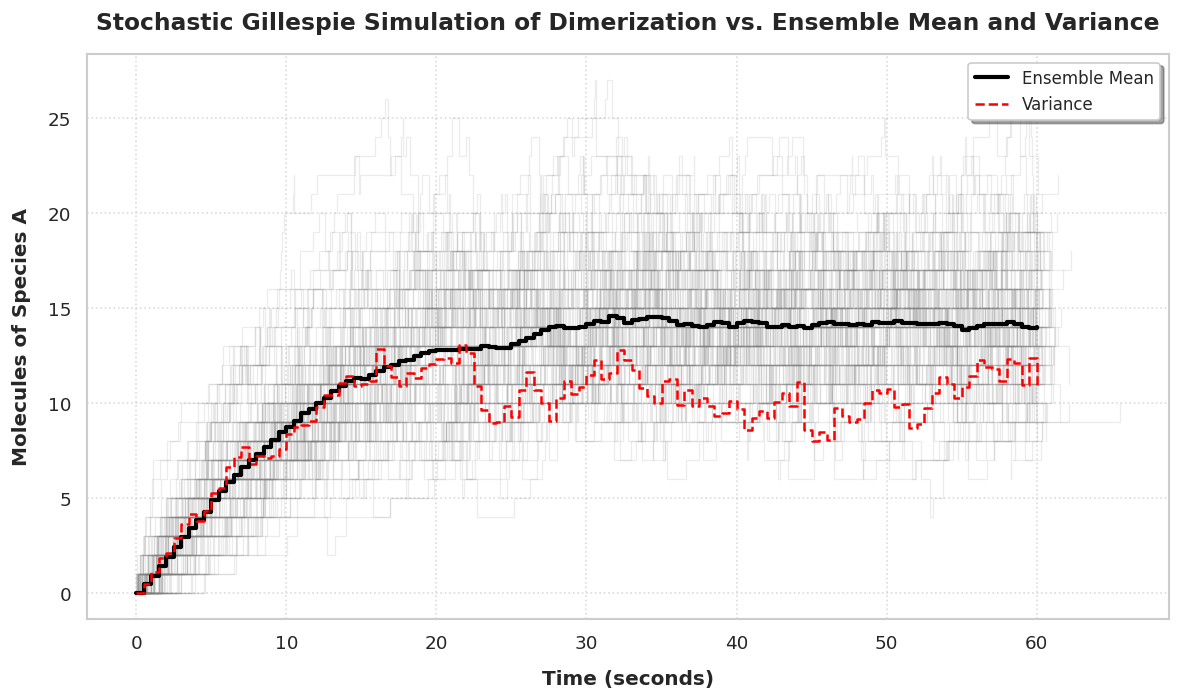

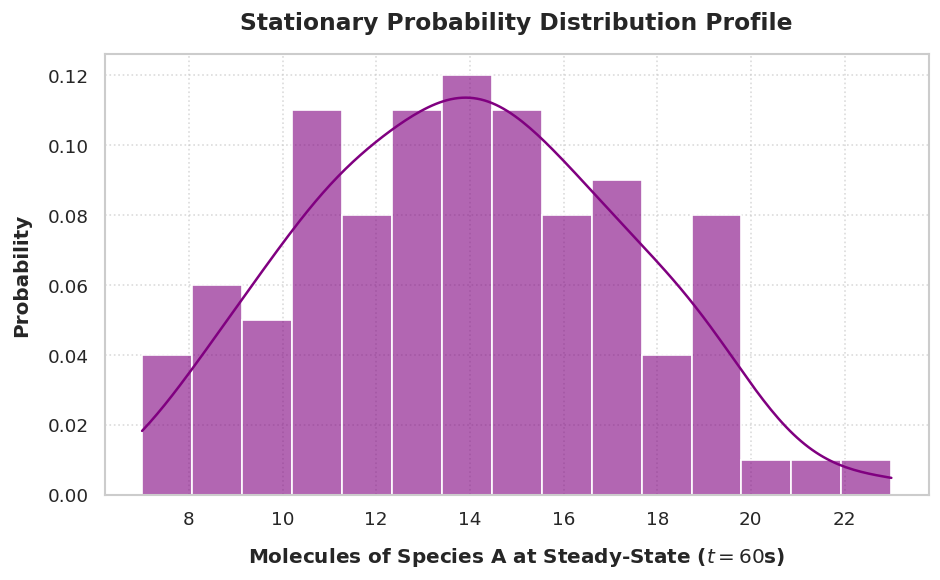

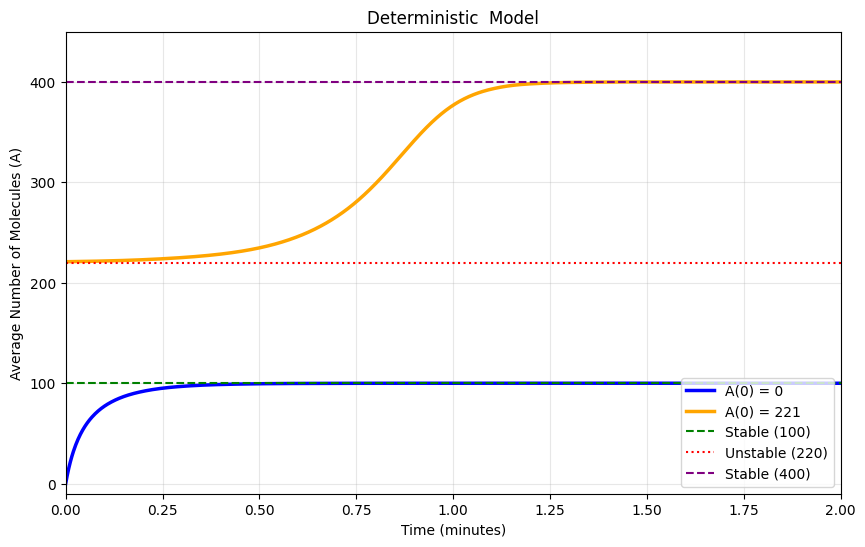

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

k1_v2 = 2.5e-4
k2_v  = 0.18
k3    = 37.5
k4_v  = 2200.0

def schlogl_ode(t, A):
    dAdt= -k1_v2 * A**3 + k2_v * A**2 - k3 * A + k4_v
    return  dAdt
t_span = (0.0, 2.0)
t_eval = np.linspace(t_span[0], t_span[1], 1000)
A_low=[0.0]
A_high=[221.0]
sol_low = solve_ivp(schlogl_ode, t_span, A_low, t_eval=t_eval)
sol_high = solve_ivp(schlogl_ode, t_span, A_high, t_eval=t_eval)

plt.figure(figsize=(10, 6))
plt.plot(sol_low.t, sol_low.y[0], color='blue', linewidth=2.5, label='A(0) = 0')
plt.plot(sol_high.t, sol_high.y[0], color='orange', linewidth=2.5, label='A(0) = 221')

plt.axhline(y=100, color='green', linestyle='--', linewidth=1.5, label='Stable (100)')
plt.axhline(y=220, color='red', linestyle=':', linewidth=1.5, label='Unstable (220)')
plt.axhline(y=400, color='purple', linestyle='--', linewidth=1.5, label='Stable (400)')

plt.title('Deterministic  Model')
plt.xlabel('Time (minutes)')
plt.ylabel('Average Number of Molecules (A)')
plt.xlim(t_span)
plt.ylim(-10, 450)
plt.grid(True, alpha=0.3)
plt.legend(loc='lower right')
plt.show()

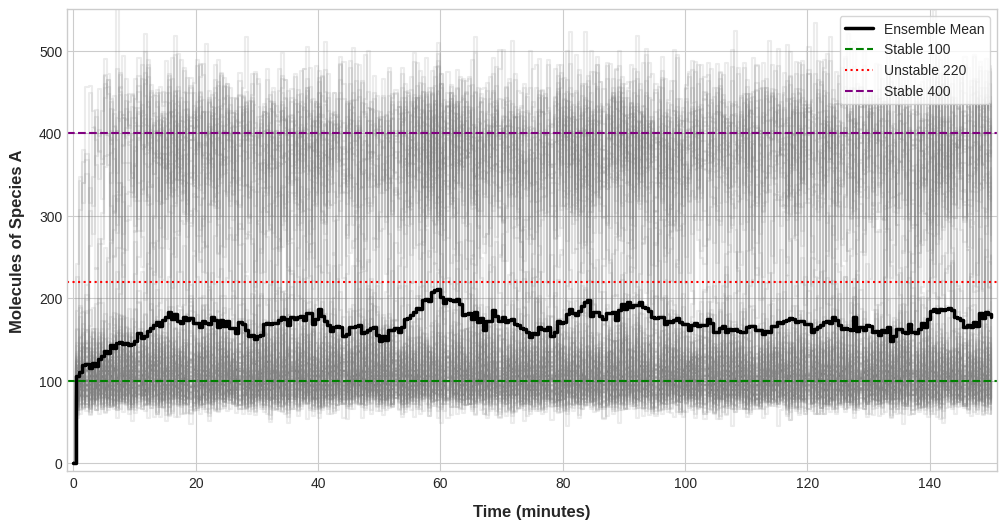

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit

# Kinetic rate constants for Schlögl-like trimolecular system
k1 = 2.5e-4
k2 = 0.18
k3 = 37.5
k4 = 2200.0

# Simulation time configurations
mt = 150
dt = 0.5

@njit
def rxn(A_init, k1, k2, k3, k4, mt, dt, conc, idx):
    A = A_init

    # Calculate combinatorial propensities for 3rd, 2nd, 1st, and 0th order reactions
    a1 = k1 * A * (A - 1) * (A - 2)
    a2 = k2 * A * (A - 1)
    a3 = k3 * A
    a4 = k4
    a0 = a1 + a2 + a3 + a4

    t = 0.0
    t2 = 0.0
    j = 0

    # Store initial condition at t=0
    conc[idx, 0] = A

    while True:
        # Exit if maximum timeline is breached or system hits total deadlock
        if(t >= mt or t2 >= mt or a0 == 0):
            break

        # Gillespie step 1: Sample waiting time tau using a random float r1
        r1 = random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        # Gillespie step 2: Sample which reaction occurs using a random float r2
        r2 = random.random()

        # Synchronize discrete event timeline (t) onto the uniform observation grid (t2)
        while (t2 + dt) <= t and (t2 + dt) <= mt:
            j += 1
            t2 += dt
            if j >= conc.shape[1]:
                break
            conc[idx, j] = A

        # Update molecule count based on which propensity interval r2 falls into
        if (r2 * a0) <= a1:
            A = A - 1  # Trimolecular consumption reaction
        elif (r2 * a0) <= (a1 + a2):
            A = A + 1  # Bimolecular production reaction
        elif (r2 * a0) <= (a1 + a2 + a3):
            A = A - 1  # Unimolecular degradation reaction
        else:
            A = A + 1  # Constant baseline influx reaction

        # Re-evaluate all state-dependent propensities and total hazard for next iteration
        a1 = k1 * A * (A - 1) * (A - 2)
        a2 = k2 * A * (A - 1)
        a3 = k3 * A
        a4 = k4
        a0 = a1 + a2 + a3 + a4

# Setup uniform observation time grid
meantime = np.arange(0, 150.001, 0.5)

# Master matrix to hold 100 simulation rows across 301 grid coordinates
conc = np.zeros((100, len(meantime)))

# Run 100 independent stochastic trajectories initialized from 0 molecules
for i in range(100):
    rxn(0, k1, k2, k3, k4, mt, dt, conc, i)

# Initialize canvas space for visualization
plt.figure(figsize=(12, 6))

# Plot all 100 raw stochastic trajectories as a faint background cloud
for i in range(100):
    plt.step(meantime, conc[i, :], where='post', alpha=0.15, color='gray')

# Plot the statistical ensemble average across all paths
plt.step(meantime, np.mean(conc, axis=0), where='post', label='Ensemble Mean', color='black', linewidth=2.5)

# Plot horizontal lines representing the theoretical steady states of the system
plt.axhline(y=100, color='green', linestyle='--', label='Stable 100')
plt.axhline(y=220, color='red', linestyle=':', label='Unstable 220')
plt.axhline(y=400, color='purple', linestyle='--', label='Stable 400')

# Visual structural formatting for the graph
plt.xlabel('Time (minutes)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Molecules of Species A', fontsize=12, fontweight='bold', labelpad=10)
plt.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
plt.xlim(-1.0, 151.0)
plt.ylim(-10, 550)
plt.show()

[400. 220. 100.]


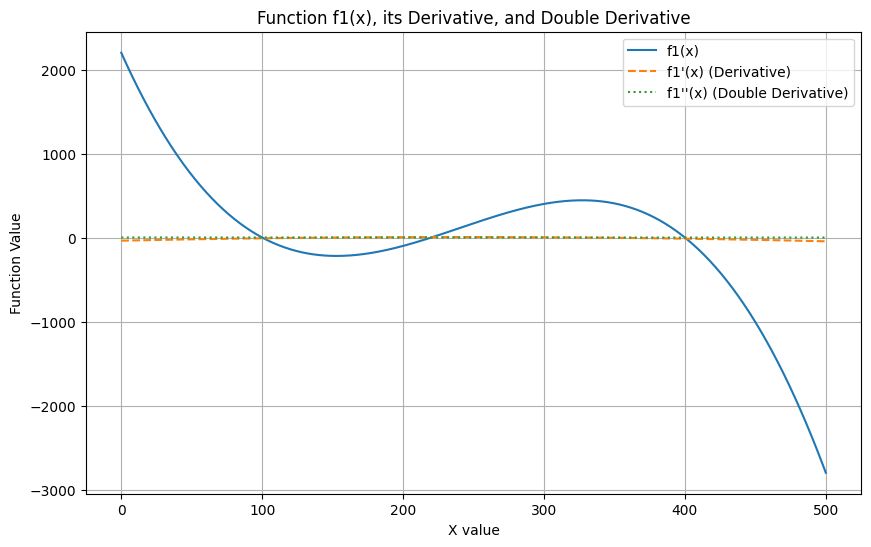

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp

k1=2.5*(10**-4)
k2=0.18
k3=37.5
k4=2200
y=np.linspace(0,500,500)

x=sp.symbols('x')
def f1(x):
 f1_expr = -k1*(x**3)+k2*(x**2)-k3*x+k4
 return f1_expr

# Calculate the derivative of f1 with respect to x
df1_dx = sp.diff(f1(x), x)

# Calculate the second derivative of f1 with respect to x
d2f1_dx2 = sp.diff(f1(x), x, 2)

# Convert the symbolic derivative to a numerical function for plotting
df1_dx_numeric = sp.lambdify(x, df1_dx, 'numpy')
d2f1_dx2_numeric = sp.lambdify(x, d2f1_dx2, 'numpy')

roots=np.roots([-k1,k2,-k3,k4])
print(roots)

plt.figure(figsize=(10, 6))
plt.plot(y,f1(y), label='f1(x)')
plt.plot(y, df1_dx_numeric(y), label="f1'(x) (Derivative)", linestyle='--')
plt.plot(y, d2f1_dx2_numeric(y), label="f1''(x) (Double Derivative)", linestyle=':')

plt.grid(True)
plt.xlabel("X value")
plt.ylabel("Function Value")
plt.title("Function f1(x), its Derivative, and Double Derivative")
plt.legend()
plt.show()

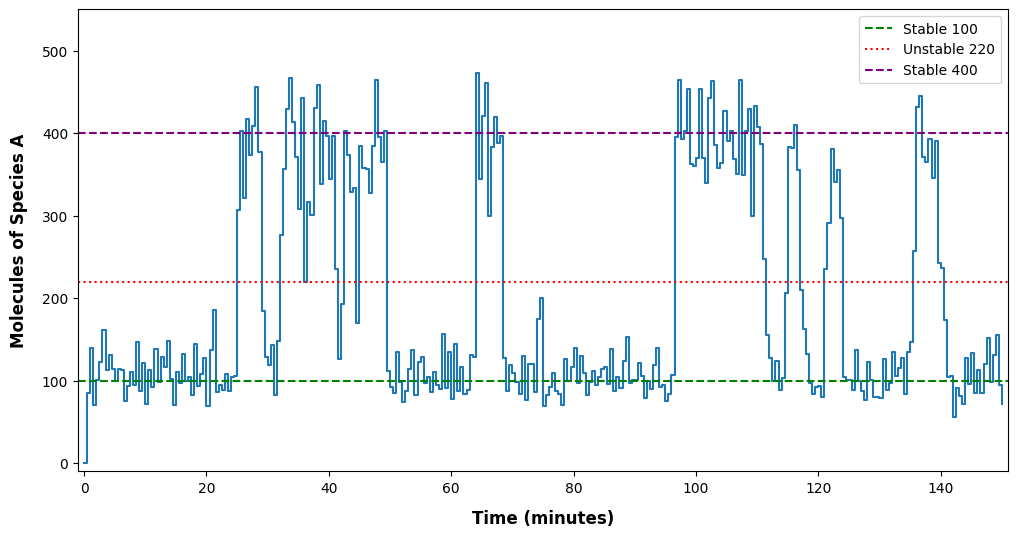

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit

# Kinetic rate constants for Schlögl-like trimolecular system
k1 = 2.5e-4
k2 = 0.18
k3 = 37.5
k4 = 2200.0

# Simulation time configurations
mt = 150
dt = 0.5

@njit
def rxn(A_init, k1, k2, k3, k4, mt, dt, conc, idx):
    A = A_init

    # Calculate combinatorial propensities for 3rd, 2nd, 1st, and 0th order reactions
    a1 = k1 * A * (A - 1) * (A - 2)
    a2 = k2 * A * (A - 1)
    a3 = k3 * A
    a4 = k4
    a0 = a1 + a2 + a3 + a4

    t = 0.0
    t2 = 0.0
    j = 0

    # Store initial condition at t=0
    conc[idx, 0] = A

    while True:
        # Exit if maximum timeline is breached or system hits total deadlock
        if(t >= mt or t2 >= mt or a0 == 0):
            break

        # Gillespie step 1: Sample waiting time tau using a random float r1
        r1 = random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        # Gillespie step 2: Sample which reaction occurs using a random float r2
        r2 = random.random()

        # Synchronize discrete event timeline (t) onto the uniform observation grid (t2)
        while (t2 + dt) <= t and (t2 + dt) <= mt:
            j += 1
            t2 += dt
            if j >= conc.shape[1]:
                break
            conc[idx, j] = A

        # Update molecule count based on which propensity interval r2 falls into
        if (r2 * a0) <= a1:
            A = A - 1  # Trimolecular consumption reaction
        elif (r2 * a0) <= (a1 + a2):
            A = A + 1  # Bimolecular production reaction
        elif (r2 * a0) <= (a1 + a2 + a3):
            A = A - 1  # Unimolecular degradation reaction
        else:
            A = A + 1  # Constant baseline influx reaction

        # Re-evaluate all state-dependent propensities and total hazard for next iteration
        a1 = k1 * A * (A - 1) * (A - 2)
        a2 = k2 * A * (A - 1)
        a3 = k3 * A
        a4 = k4
        a0 = a1 + a2 + a3 + a4

# Setup uniform observation time grid
meantime = np.arange(0, 150.001, 0.5)

# Master matrix to hold 100 simulation rows across 301 grid coordinates
conc = np.zeros((1, len(meantime)))

# Run 100 independent stochastic trajectories initialized from 0 molecules
for i in range(1):
    rxn(0, k1, k2, k3, k4, mt, dt, conc, i)

# Initialize canvas space for visualization
plt.figure(figsize=(12, 6))

# Plot all  raw stochastic trajectories as a faint background cloud
for i in range(1):
    plt.step(meantime, conc[i, :], where='post')

# Plot the statistical ensemble average across all paths
#plt.step(meantime, np.mean(conc, axis=0), where='post', label='Ensemble Mean', color='black', linewidth=2.5)

# Plot horizontal lines representing the theoretical steady states of the system
plt.axhline(y=100, color='green', linestyle='--', label='Stable 100')
plt.axhline(y=220, color='red', linestyle=':', label='Unstable 220')
plt.axhline(y=400, color='purple', linestyle='--', label='Stable 400')

# Visual structural formatting for the graph
plt.xlabel('Time (minutes)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Molecules of Species A', fontsize=12, fontweight='bold', labelpad=10)
plt.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
plt.xlim(-1.0, 151.0)
plt.ylim(-10, 550)
plt.show()

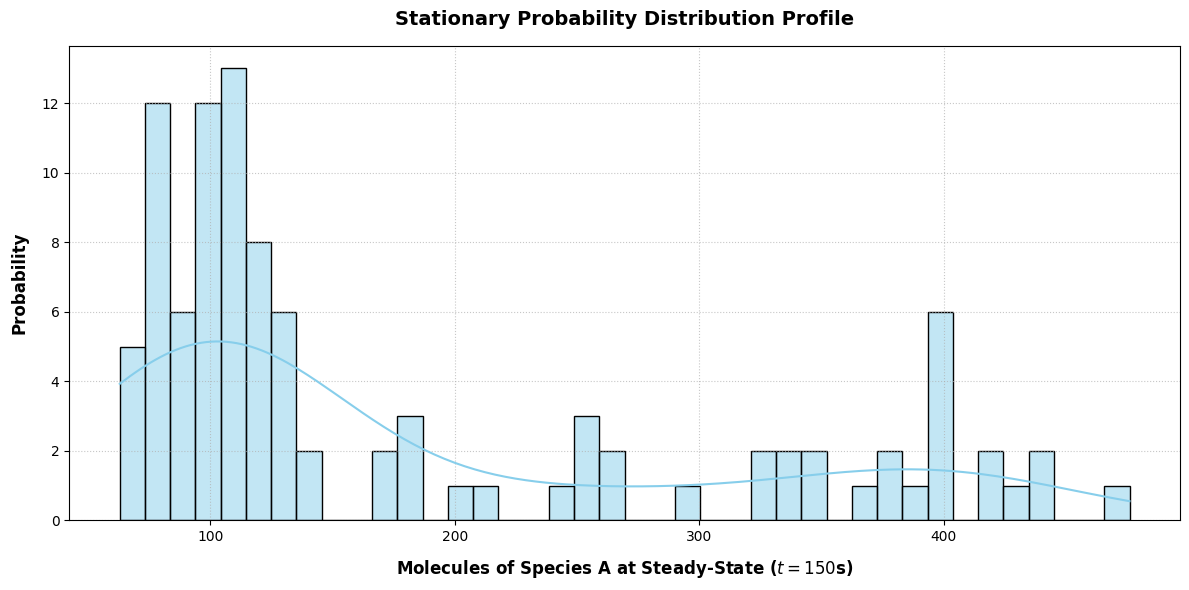

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit
import seaborn as sns

# Kinetic rate constants for Schlögl-like trimolecular system
k1 = 2.5e-4
k2 = 0.18
k3 = 37.5
k4 = 2200.0

# Simulation time configurations
mt = 150
dt = 0.5

@njit
def rxn(A_init, k1, k2, k3, k4, mt, dt, conc, idx):
    A = A_init

    # Calculate combinatorial propensities for 3rd, 2nd, 1st, and 0th order reactions
    a1 = k1 * A * (A - 1) * (A - 2)
    a2 = k2 * A * (A - 1)
    a3 = k3 * A
    a4 = k4
    a0 = a1 + a2 + a3 + a4

    t = 0.0
    t2 = 0.0
    j = 0

    # Store initial condition at t=0
    conc[idx, 0] = A

    while True:
        # Exit if maximum timeline is breached or system hits total deadlock
        if(t >= mt or t2 >= mt or a0 == 0):
            break

        # Gillespie step 1: Sample waiting time tau using a random float r1
        r1 = random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        # Gillespie step 2: Sample which reaction occurs using a random float r2
        r2 = random.random()

        # Synchronize discrete event timeline (t) onto the uniform observation grid (t2)
        while (t2 + dt) <= t and (t2 + dt) <= mt:
            j += 1
            t2 += dt
            if j >= conc.shape[1]:
                break
            conc[idx, j] = A

        # Update molecule count based on which propensity interval r2 falls into
        if (r2 * a0) <= a1:
            A = A - 1  # Trimolecular consumption reaction
        elif (r2 * a0) <= (a1 + a2):
            A = A + 1  # Bimolecular production reaction
        elif (r2 * a0) <= (a1 + a2 + a3):
            A = A - 1  # Unimolecular degradation reaction
        else:
            A = A + 1  # Constant baseline influx reaction

        # Re-evaluate all state-dependent propensities and total hazard for next iteration
        a1 = k1 * A * (A - 1) * (A - 2)
        a2 = k2 * A * (A - 1)
        a3 = k3 * A
        a4 = k4
        a0 = a1 + a2 + a3 + a4

# Setup uniform observation time grid
meantime = np.arange(0, 150.001, 0.5)

# Master matrix to hold 100 simulation rows across 301 grid coordinates
conc = np.zeros((100, len(meantime)))

# Run 100 independent stochastic trajectories initialized from 0 molecules
for i in range(100):
    rxn(0, k1, k2, k3, k4, mt, dt, conc, i)

# Initialize canvas space for visualization
plt.figure(figsize=(12, 6))

stationary_states=conc[:,-1]
sns.histplot(stationary_states, bins=40, kde=True, color='skyblue')
plt.xlabel('Molecules of Species A at Steady-State ($t = 150$s)', fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel('Probability', fontsize=12, fontweight='bold', labelpad=10)
plt.title('Stationary Probability Distribution Profile', fontsize=14, fontweight='bold', pad=15)
plt.grid(True, linestyle=':', alpha=0.7)
plt.tight_layout()

<function matplotlib.pyplot.show(close=None, block=None)>

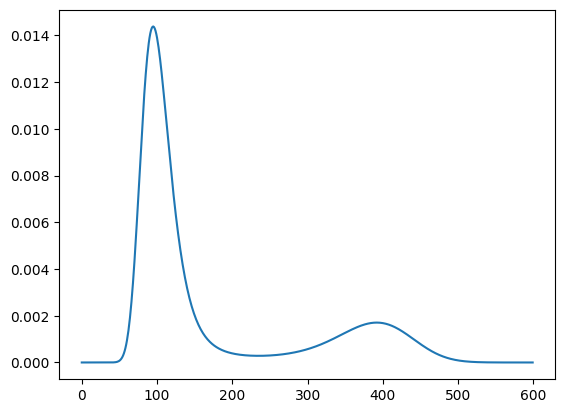

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
import random
from numba import njit

k1 = 2.5e-4
k2 = 0.18
k3 = 37.5
k4 = 2200.0

n=600
phi=np.zeros(600)
phi[0]=1
def bin(val,i):
  sol=val*((k2*i*(i-1)+k4)/(k1*(i+1)*i*(i-1)+k3*(i+1)))
  return sol
for i in range(0,n-1,1):
  phi[i+1]=bin(phi[i],i)
#print(phi)
phi=phi/np.sum(phi)
plt.plot(range(n),phi)
plt.show

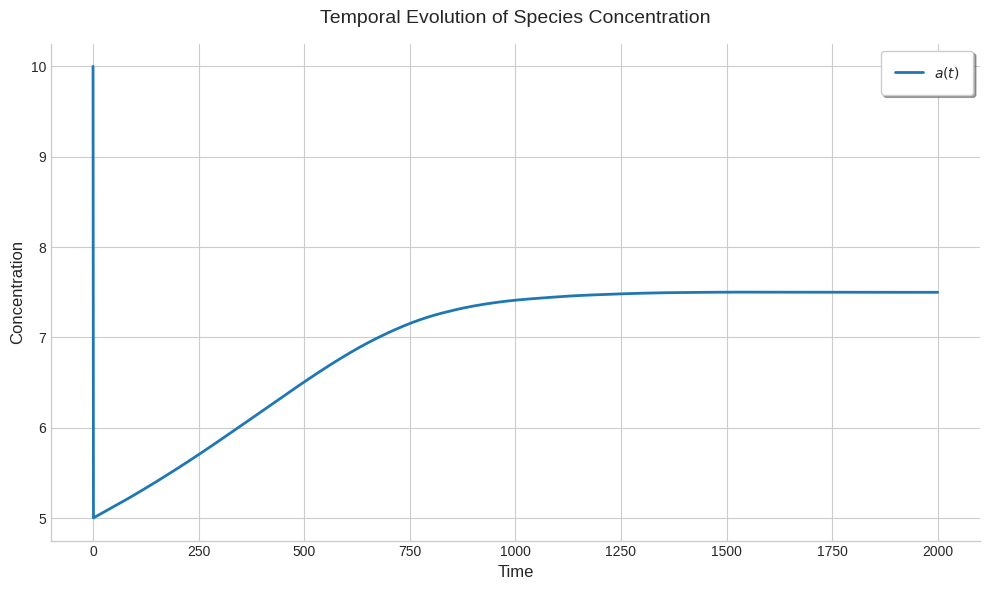

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
import math
import random
from numba import njit

k1=4.0e-5
k2=50
k3=10
k4=25

def system(t,space):
  a,b=space
  dadt=(k1*(a**2)*b)+k2-(k3*a)
  dbdt=(-k1*(a**2)*b)+k4
  return [dadt,dbdt]
y0=[10.0,10.0]
t=np.linspace(0,2000,2000)
sol=solve_ivp(system,(t[0],t[-1]),y0,t_eval=t,method='BDF')
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 6), dpi=100)

ax.plot(sol.t, sol.y[0], label=r'$a(t)$', linewidth=2, color='#1f77b4')
#ax.plot(sol.t, sol.y[1], label=r'$b(t)$', linewidth=2, color='#ff7f0e')

ax.set_title("Temporal Evolution of Species Concentration", fontsize=14, pad=15)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Concentration", fontsize=12)

ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=True, shadow=True, borderpad=1)

plt.tight_layout()
plt.show()


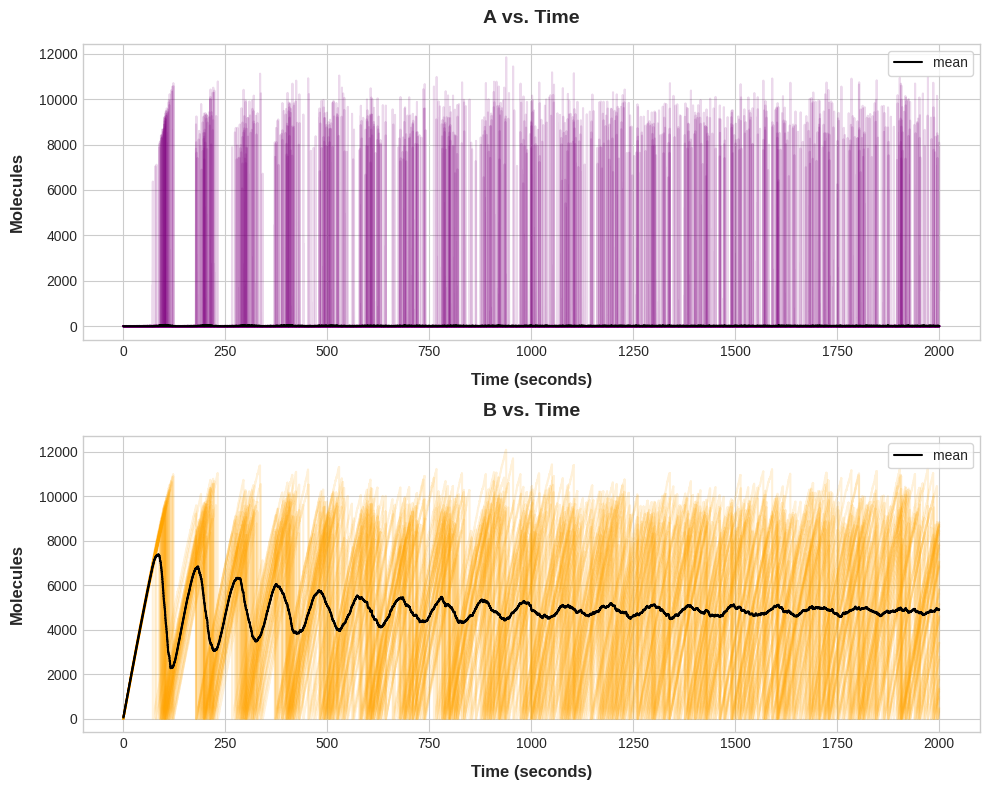

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numba import njit

meantime = np.arange(0, 2000.001, 0.5)
conca = np.zeros((1000, 4001))
concb = np.zeros((1000, 4001))
a = 10.0
b = 10.0

@njit
def pro(k1, k2, k3, k4, a, b, i, conca, concb):
    conca[i, 0] = a
    concb[i, 0] = b
    t = 0
    t2 = 0
    dt = 0.5
    mt = 2000
    j = 0
    CA = [a]
    CB = [b]
    times = [t]

    while True:
        if t >= mt or t2 >= mt:
            break
        if j >= conca.shape[1]:
            break
        a1 = k1 * a * (a - 1) * b
        a2 = k2
        a3 = k3 * a
        a4 = k4
        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            break

        r1 = np.random.random()
        tau = (1 / a0) * math.log(1 / r1)
        t += tau
        r2 = np.random.random()

        while (t2 + dt) <= t:
            j = j + 1
            t2 += dt
            if j >= conca.shape[1]:
                break
            conca[i, j] = a
            concb[i, j] = b

        if (r2 * a0) <= a1:
            a = a + 1
            b = b - 1
        elif (r2 * a0) <= a1 + a2 and (r2 * a0) > a1:
            a = a + 1
        elif (r2 * a0) <= a1 + a2 + a3 and (r2 * a0) > a1 + a2:
            a = a - 1
        else:
            b = b + 1

        if j >= conca.shape[1]:
            break

        conca[i, j] = a
        concb[i, j] = b
        CA.append(a)
        CB.append(b)
        times.append(t)

    return CA, CB, times

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

for i in range(1000):
    k1 = 4.0e-5
    k2 = 50.0
    k3 = 10.0
    k4 = 100.0
    CA, CB, times = pro(k1, k2, k3, k4, a, b, i, conca, concb)

    if i < 50:
        axes[0].step(times, CA, where='post', alpha=0.15, color='purple')
        axes[1].step(times, CB, where='post', alpha=0.15, color='orange')

mean_a = np.mean(conca, axis=0)
mean_b = np.mean(concb, axis=0)
var_a = np.var(conca, axis=0)
var_b = np.var(concb, axis=0)

axes[0].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_ylabel('Molecules', fontsize=12, fontweight='bold', labelpad=10)
axes[0].set_title('A vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[1].set_title('B vs. Time', fontsize=14, fontweight='bold', pad=15)

axes[0].step(meantime, mean_a, where='post', label='mean', color='black')
axes[1].step(meantime, mean_b, where='post', label='mean', color='black')

axes[0].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')
axes[1].legend(loc='upper right', fontsize=10, frameon=True, facecolor='white')

plt.tight_layout()
plt.show()

Analytical Peak Coordinate (a_m, b_m): (10.0, 12500.0)


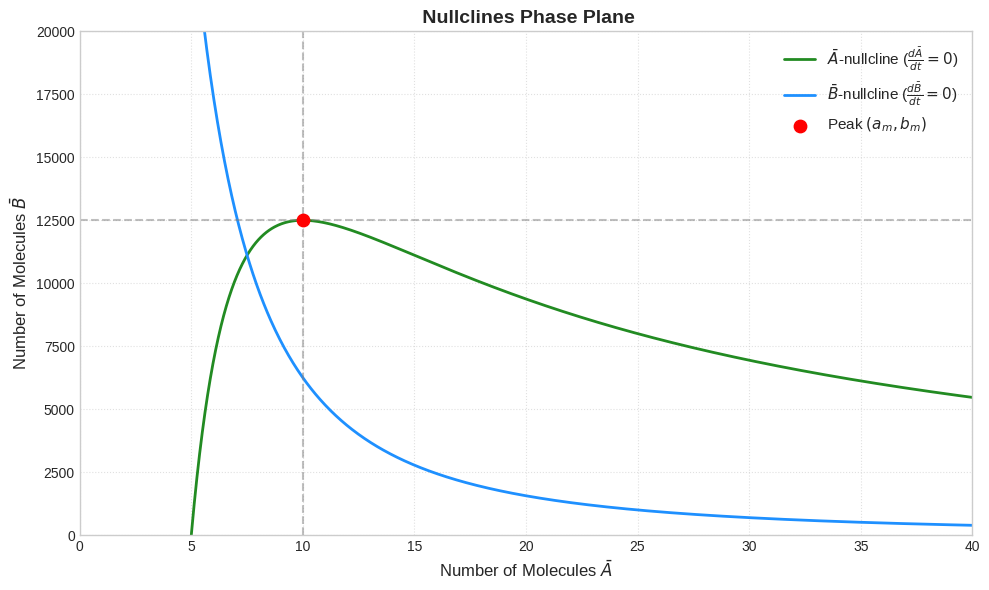

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

K1 = 4.0e-5
K2 = 50.0
K3 = 10.0
K4 = 25

a_m = (2 * K2) / K3
b_m = K3**2 / (4 * K1 * K2)
print(f"Analytical Peak Coordinate (a_m, b_m): ({a_m:.1f}, {b_m:.1f})")

A_vals = np.linspace(0.1, 40, 1000)

B_nullcline_A = (K3 * A_vals - K2) / (K1 * A_vals**2)
B_nullcline_B = K4 / (K1 * A_vals**2)

plt.figure(figsize=(10, 6), dpi=100)

plt.plot(A_vals, B_nullcline_A, label=r'$\bar{A}$-nullcline ($\frac{d\bar{A}}{dt}=0$)', color='forestgreen', linewidth=2)
plt.plot(A_vals, B_nullcline_B, label=r'$\bar{B}$-nullcline ($\frac{d\bar{B}}{dt}=0$)', color='dodgerblue', linewidth=2)

plt.scatter(a_m, b_m, color='red', s=80, zorder=5, label=r'Peak $(a_m, b_m)$')
plt.axvline(x=a_m, color='gray', linestyle='--', alpha=0.5)
plt.axhline(y=b_m, color='gray', linestyle='--', alpha=0.5)

plt.xlim(0, 40)
plt.ylim(0, 20000)

plt.title(' Nullclines Phase Plane', fontsize=14, fontweight='bold')
plt.xlabel(r'Number of Molecules $\bar{A}$', fontsize=12)
plt.ylabel(r'Number of Molecules $\bar{B}$', fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(fontsize=11, loc='upper right')

plt.tight_layout()
plt.show()

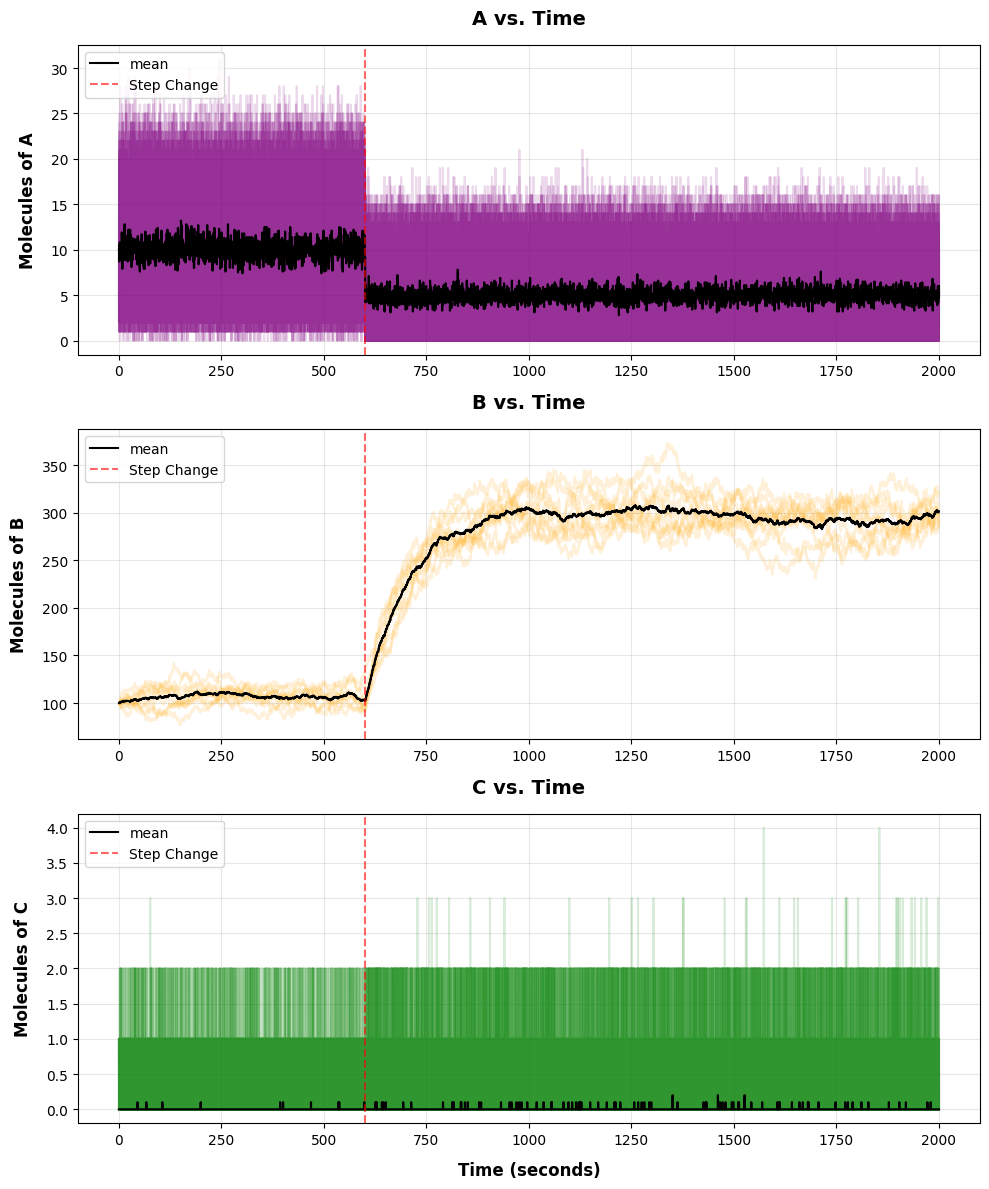

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numba import njit

meantime = np.arange(0, 2000.001, 0.5)
conca = np.zeros((10, 4001))
concb = np.zeros((10, 4001))
concc = np.zeros((10, 4001))

a_init = 10.0
b_init = 100.0
c_init = 0.0

@njit
def pro(k1, k2, k3, k4, k5, k6, a_in, b_in, c_in, i, conca, concb, concc):
    conca[i, 0] = a_in
    concb[i, 0] = b_in
    concc[i, 0] = c_in
    t = 0.0
    t2 = 0.0
    dt = 0.5
    mt = 2000.0
    j = 0

    max_steps = 100000
    CA = np.zeros(max_steps)
    CB = np.zeros(max_steps)
    CC = np.zeros(max_steps)
    times = np.zeros(max_steps)

    CA[0] = a_in
    CB[0] = b_in
    CC[0] = c_in
    times[0] = t
    step_idx = 1

    a = a_in
    b = b_in
    c = c_in

    current_k5 = k5
    max_j = conca.shape[1]

    while True:
        if t >= mt or t2 >= mt:
            break
        if j >= max_j:
            break

        if t >= 600.0:
            current_k5 = 500.0
        else:
            current_k5 = k5

        a1 = k1
        a2 = k2 * c
        a3 = k3 * b
        a4 = k4 * a * c
        a5 = current_k5
        a6 = k6 * a
        a0 = a1 + a2 + a3 + a4 + a5 + a6

        if a0 == 0.0:
            break

        r1 = np.random.random()
        tau = -math.log(r1) / a0
        t += tau
        r2 = np.random.random()

        while (t2 + dt) <= t:
            j += 1
            t2 += dt
            if j >= max_j:
                break
            conca[i, j] = a
            concb[i, j] = b
            concc[i, j] = c

        amphi = r2 * a0
        if amphi <= a1:
            c += 1.0
        elif amphi <= a1 + a2:
            c -= 1.0
            b += 1.0
        elif amphi <= a1 + a2 + a3:
            b -= 1.0
        elif amphi <= a1 + a2 + a3 + a4:
            c -= 1.0
        elif amphi <= a1 + a2 + a3 + a4 + a5:
            a += 1.0
        else:
            a -= 1.0

        if j >= max_j:
            break

        if step_idx >= max_steps:
            new_max = max_steps * 2
            new_CA = np.zeros(new_max)
            new_CB = np.zeros(new_max)
            new_CC = np.zeros(new_max)
            new_times = np.zeros(new_max)
            new_CA[:max_steps] = CA
            new_CB[:max_steps] = CB
            new_CC[:max_steps] = CC
            new_times[:max_steps] = times
            CA = new_CA
            CB = new_CB
            CC = new_CC
            times = new_times
            max_steps = new_max

        CA[step_idx] = a
        CB[step_idx] = b
        CC[step_idx] = c
        times[step_idx] = t
        step_idx += 1

    return CA[:step_idx], CB[:step_idx], CC[:step_idx], times[:step_idx]

fig, axes = plt.subplots(3, 1, figsize=(10, 12))

k1 = 100.0
k2 = 1000.0
k3 = 0.01
k4 = 9900.0
k5 = 1000.0
k6 = 100.0

for i in range(10):
    CA, CB, CC, times = pro(k1, k2, k3, k4, k5, k6, a_init, b_init, c_init, i, conca, concb, concc)

    axes[0].step(times, CA, where='post', alpha=0.15, color='purple')
    axes[1].step(times, CB, where='post', alpha=0.15, color='orange')
    axes[2].step(times, CC, where='post', alpha=0.15, color='green')

mean_a = np.mean(conca, axis=0)
mean_b = np.mean(concb, axis=0)
mean_c = np.mean(concc, axis=0)

axes[0].set_ylabel('Molecules of A', fontsize=12, fontweight='bold', labelpad=10)
axes[1].set_ylabel('Molecules of B', fontsize=12, fontweight='bold', labelpad=10)
axes[2].set_ylabel('Molecules of C', fontsize=12, fontweight='bold', labelpad=10)
axes[2].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold', labelpad=10)

axes[0].set_title('A vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[1].set_title('B vs. Time', fontsize=14, fontweight='bold', pad=15)
axes[2].set_title('C vs. Time', fontsize=14, fontweight='bold', pad=15)

axes[0].step(meantime, mean_a, where='post', label='mean', color='black')
axes[1].step(meantime, mean_b, where='post', label='mean', color='black')
axes[2].step(meantime, mean_c, where='post', label='mean', color='black')

for ax in axes:
    ax.axvline(600, color='red', linestyle='--', alpha=0.6, label='Step Change')
    ax.legend(loc='upper left', fontsize=10, frameon=True, facecolor='white')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

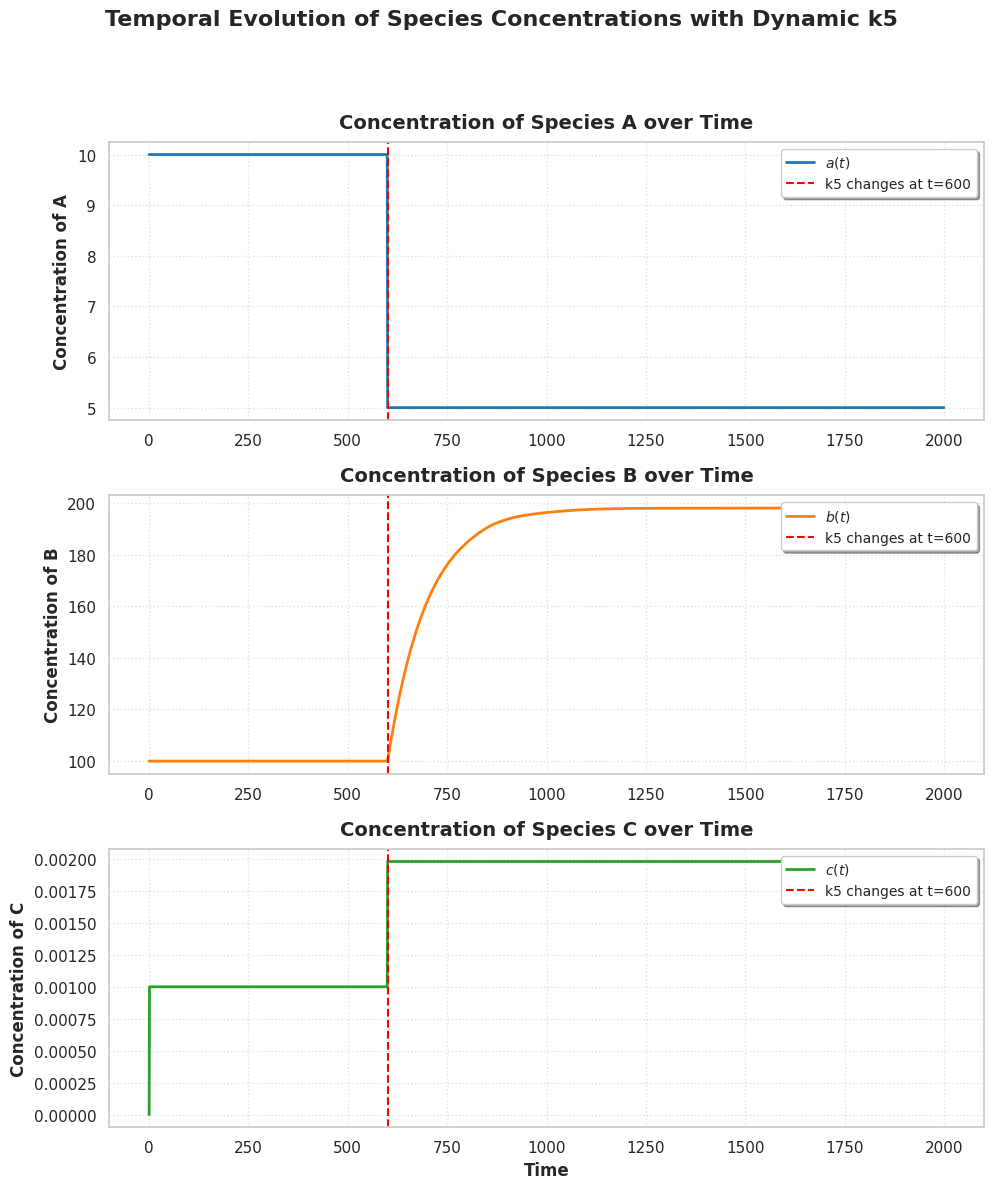

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from numba import njit
import seaborn as sns # Import seaborn for better aesthetics

k1 = 100.0
k2 = 1000.0
k3 = 0.01
k4 = 9900.0
k5 = 1000.0
k6 = 100.0

def system(t,space):
  if t>=600.0:
    k5=500.0
  else:
    k5=1000.0
  a,b,c=space
  dadt=k5-k6*a
  dbdt=k2*c-k3*b
  dcdt=k1-k2*c-k4*a*c
  return [dadt,dbdt,dcdt]
y0=[10.0,100.0,0.0]
t=np.linspace(0,2000,2000)
sol=solve_ivp(system,(t[0],t[-1]),y0,t_eval=t,method='BDF')

# Apply seaborn style for better aesthetics
sns.set_theme(style="whitegrid")

fig,axes=plt.subplots(3,1,figsize=(10,12))

axes[0].plot(sol.t,sol.y[0],label=r'$a(t)$',linewidth=2,color='#1f77b4')
axes[1].plot(sol.t,sol.y[1],label=r'$b(t)$',linewidth=2,color='#ff7f0e')
axes[2].plot(sol.t,sol.y[2],label=r'$c(t)$',linewidth=2,color='#2ca02c')

# Add titles and labels for clarity
axes[0].set_title('Concentration of Species A over Time', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Concentration of A', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title('Concentration of Species B over Time', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Concentration of B', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].set_title('Concentration of Species C over Time', fontsize=14, fontweight='bold', pad=10)
axes[2].set_xlabel('Time', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Concentration of C', fontsize=12, fontweight='bold')
axes[2].legend(loc='upper right', fontsize=10)
axes[2].grid(True, linestyle=':', alpha=0.6)

# Add a vertical line to indicate the change in k5
for ax in axes:
    ax.axvline(600.0, color='red', linestyle='--', label='k5 changes at t=600')
    ax.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white', shadow=True)


plt.suptitle('Temporal Evolution of Species Concentrations with Dynamic k5', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent overlap, leaving space for suptitle
plt.show()

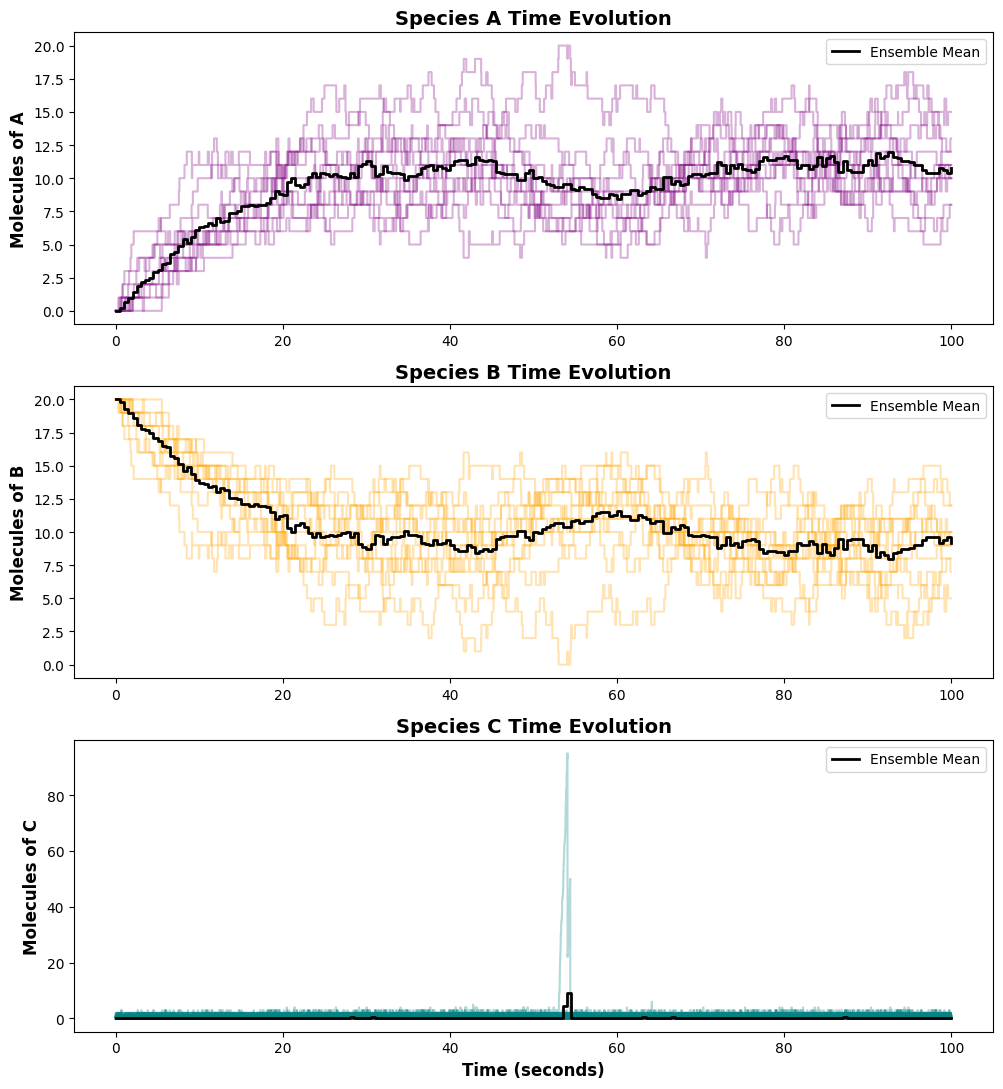

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numba import njit

dt = 0.5
t_max = 100.0
meantime = np.arange(0, t_max + dt/2, dt)
num_steps = len(meantime)
num_simulations = 10

conca = np.zeros((num_simulations, num_steps))
concb = np.zeros((num_simulations, num_steps))
concc = np.zeros((num_simulations, num_steps))

init_a = 0.0
init_b = 20.0
init_c = 0.0

@njit
def gillespie_ssa(k1, k2_v, k3_v, k4_v, init_a, init_b, init_c, i, conca, concb, concc, t_max, dt):
    a = init_a
    b = init_b
    c = init_c

    conca[i, 0] = a
    concb[i, 0] = b
    concc[i, 0] = c

    t = 0.0
    t_grid = 0.0
    j = 0

    times_log = [t]
    a_log = [a]
    b_log = [b]
    c_log = [c]

    while t < t_max:
        a1 = k1 * a
        a2 = k2_v * b * c
        a3 = k3_v
        a4 = k4_v * b * c

        a0 = a1 + a2 + a3 + a4

        if a0 == 0:
            while (j + 1) < conca.shape[1]:
                j += 1
                conca[i, j] = a
                concb[i, j] = b
                concc[i, j] = c
            break

        r1 = np.random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        while (t_grid + dt) <= t:
            j += 1
            t_grid += dt
            if j >= conca.shape[1]:
                break
            conca[i, j] = a
            concb[i, j] = b
            concc[i, j] = c

        if j >= conca.shape[1]:
            break

        r2 = np.random.random() * a0
        if r2 <= a1:
            a -= 1.0
            b += 1.0
        elif r2 <= (a1 + a2):
            b -= 1.0
            a += 1.0
        elif r2 <= (a1 + a2 + a3):
            c += 1.0
        else:
            c -= 1.0

        a_log.append(a)
        b_log.append(b)
        c_log.append(c)
        times_log.append(t)

    return a_log, b_log, c_log, times_log

k1 = 0.1
k2_v = 1.0
k3_v = 100.0
k4_v = 100.0

fig, axes = plt.subplots(3, 1, figsize=(10, 11))

for i in range(num_simulations):
    a_log, b_log, c_log, times_log = gillespie_ssa(
        k1, k2_v, k3_v, k4_v, init_a, init_b, init_c,
        i, conca, concb, concc, t_max, dt
    )

    axes[0].step(times_log, a_log, where='post', alpha=0.3, color='purple')
    axes[1].step(times_log, b_log, where='post', alpha=0.3, color='orange')
    axes[2].step(times_log, c_log, where='post', alpha=0.3, color='teal')

mean_a = np.mean(conca, axis=0)
mean_b = np.mean(concb, axis=0)
mean_c = np.mean(concc, axis=0)

axes[0].step(meantime, mean_a, where='post', label='Ensemble Mean', color='black', linewidth=2)
axes[1].step(meantime, mean_b, where='post', label='Ensemble Mean', color='black', linewidth=2)
axes[2].step(meantime, mean_c, where='post', label='Ensemble Mean', color='black', linewidth=2)

axes[0].set_ylabel('Molecules of A', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Molecules of B', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Molecules of C', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold')

axes[0].set_title('Species A Time Evolution', fontsize=14, fontweight='bold')
axes[1].set_title('Species B Time Evolution', fontsize=14, fontweight='bold')
axes[2].set_title('Species C Time Evolution', fontsize=14, fontweight='bold')

axes[0].legend(loc='upper right')
axes[1].legend(loc='upper right')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

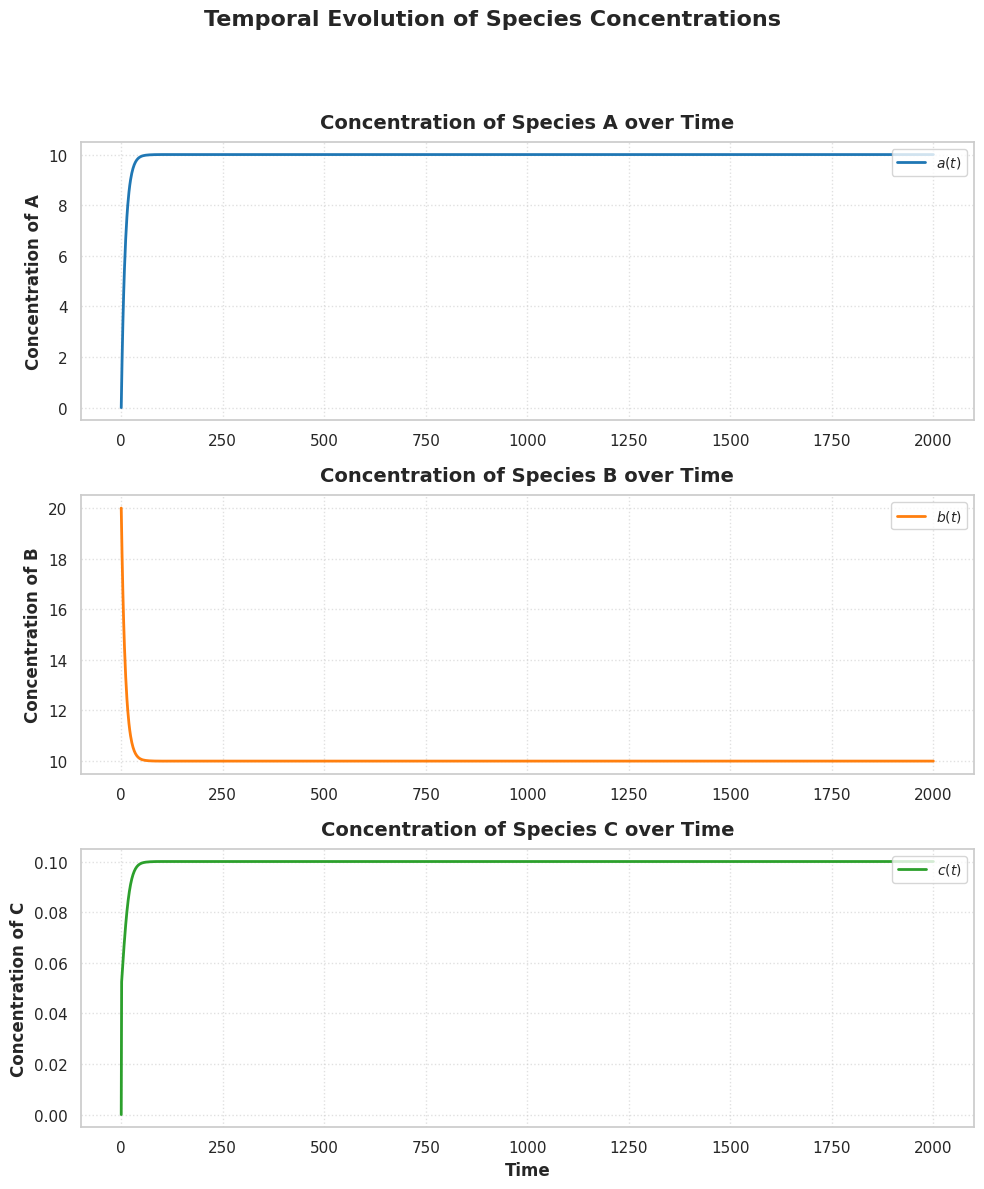

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.integrate import solve_ivp
from numba import njit
import seaborn as sns # Import seaborn for better aesthetics

k1 = 0.1
k2= 1.0
k3 = 100.0
k4 = 100.0
def system(t,space):
  a,b,c=space
  dadt=-k1*a+k2*b*c
  dbdt=k1*a-k2*b*c
  dcdt=k3-k4*b*c
  return [dadt,dbdt,dcdt]
y0=[0.0,20.0,0.0]
t=np.linspace(0,2000,2000)
sol=solve_ivp(system,(t[0],t[-1]),y0,t_eval=t,method='BDF')

# Apply seaborn style for better aesthetics
sns.set_theme(style="whitegrid")

fig,axes=plt.subplots(3,1,figsize=(10,12))

axes[0].plot(sol.t,sol.y[0],label=r'$a(t)$',linewidth=2,color='#1f77b4')
axes[1].plot(sol.t,sol.y[1],label=r'$b(t)$',linewidth=2,color='#ff7f0e')
axes[2].plot(sol.t,sol.y[2],label=r'$c(t)$',linewidth=2,color='#2ca02c')

# Add titles and labels for clarity
axes[0].set_title('Concentration of Species A over Time', fontsize=14, fontweight='bold', pad=10)
axes[0].set_ylabel('Concentration of A', fontsize=12, fontweight='bold')
axes[0].legend(loc='upper right', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].set_title('Concentration of Species B over Time', fontsize=14, fontweight='bold', pad=10)
axes[1].set_ylabel('Concentration of B', fontsize=12, fontweight='bold')
axes[1].legend(loc='upper right', fontsize=10)
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].set_title('Concentration of Species C over Time', fontsize=14, fontweight='bold', pad=10)
axes[2].set_xlabel('Time', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Concentration of C', fontsize=12, fontweight='bold')
axes[2].legend(loc='upper right', fontsize=10)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Temporal Evolution of Species Concentrations', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout(rect=[0, 0.03, 1, 0.98]) # Adjust layout to prevent overlap, leaving space for suptitle
plt.show()

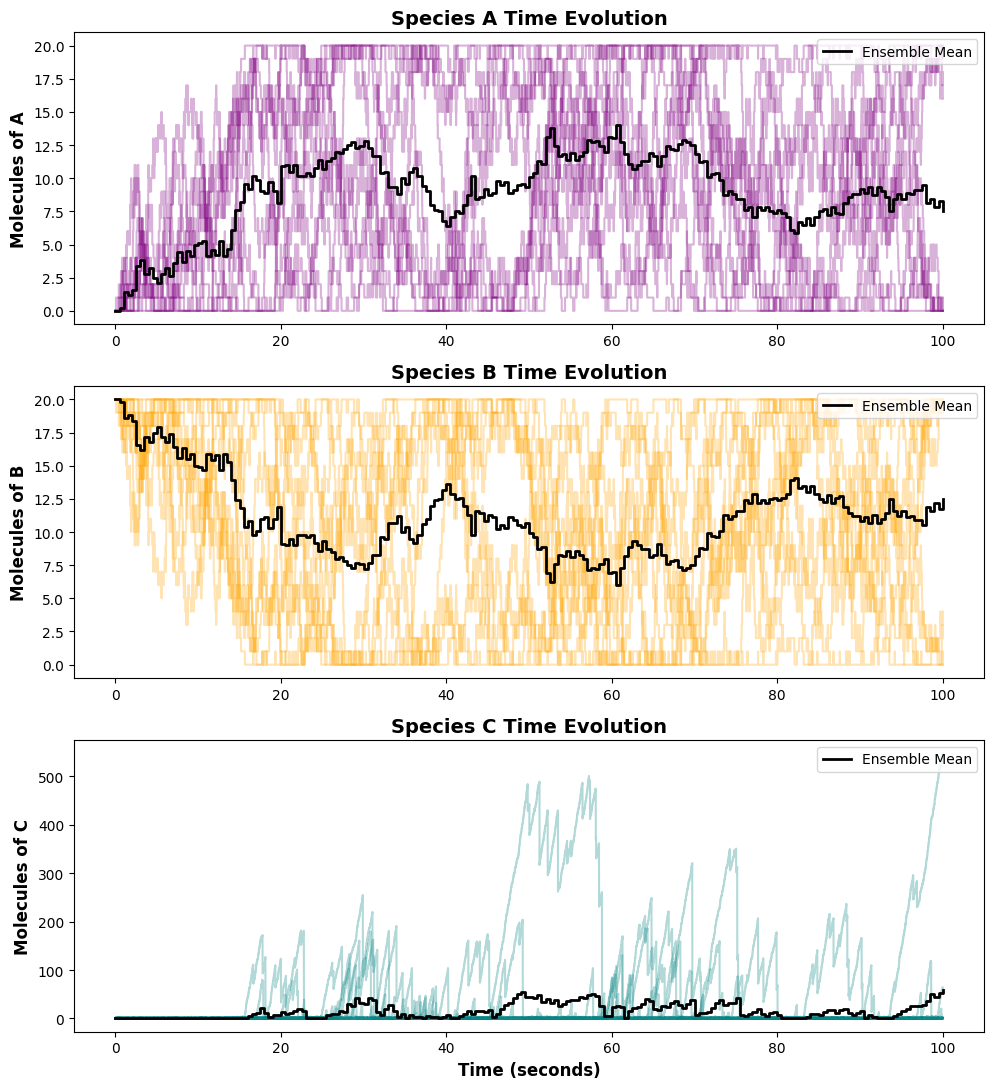

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numba import njit

dt = 0.5
t_max = 100.0
meantime = np.arange(0, t_max + dt/2, dt)
num_steps = len(meantime)
num_simulations = 10

conca = np.zeros((num_simulations, num_steps))
concb = np.zeros((num_simulations, num_steps))
concc = np.zeros((num_simulations, num_steps))

init_a = 0.0
init_b = 20.0
init_c = 0.0

@njit
def gillespie_ssa(k1, k2_v, k3_v, k4_v, k5_v, init_a, init_b, init_c, i, conca, concb, concc, t_max, dt):
    a = init_a
    b = init_b
    c = init_c

    conca[i, 0] = a
    concb[i, 0] = b
    concc[i, 0] = c

    t = 0.0
    t_grid = 0.0
    j = 0

    times_log = [t]
    a_log = [a]
    b_log = [b]
    c_log = [c]

    while t < t_max:
        a1 = k1 * a
        a2 = k2_v * b * c
        a3 = k3_v
        a4 = k4_v * b * c
        a5_reaction1 = k5_v * a * b
        a5_reaction2 = k5_v * a * b

        a0 = a1 + a2 + a3 + a4 + a5_reaction1 + a5_reaction2

        if a0 == 0:
            while (j + 1) < conca.shape[1]:
                j += 1
                conca[i, j] = a
                concb[i, j] = b
                concc[i, j] = c
            break

        r1 = np.random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        while (t_grid + dt) <= t:
            j += 1
            t_grid += dt
            if j >= conca.shape[1]:
                break
            conca[i, j] = a
            concb[i, j] = b
            concc[i, j] = c

        if j >= conca.shape[1]:
            break

        r2 = np.random.random() * a0
        if r2 <= a1:
            a -= 1.0
            b += 1.0
        elif r2 <= (a1 + a2):
            b -= 1.0
            a += 1.0
        elif r2 <= (a1 + a2 + a3):
            c += 1.0
        elif r2 <= (a1 + a2 + a3 + a4):
            c -= 1.0
        elif r2 <= (a1 + a2 + a3 + a4 + a5_reaction1):
            a += 1.0
            b -= 1.0
        else:
            a -= 1.0
            b += 1.0

        a_log.append(a)
        b_log.append(b)
        c_log.append(c)
        times_log.append(t)

    return a_log, b_log, c_log, times_log

k1 = 0.1
k2_v = 1.0
k3_v = 100.0
k4_v = 100.0
k5_v = 0.1

fig, axes = plt.subplots(3, 1, figsize=(10, 11))

for i in range(num_simulations):
    a_log, b_log, c_log, times_log = gillespie_ssa(
        k1, k2_v, k3_v, k4_v, k5_v, init_a, init_b, init_c,
        i, conca, concb, concc, t_max, dt
    )

    axes[0].step(times_log, a_log, where='post', alpha=0.3, color='purple')
    axes[1].step(times_log, b_log, where='post', alpha=0.3, color='orange')
    axes[2].step(times_log, c_log, where='post', alpha=0.3, color='teal')

mean_a = np.mean(conca, axis=0)
mean_b = np.mean(concb, axis=0)
mean_c = np.mean(concc, axis=0)

axes[0].step(meantime, mean_a, where='post', label='Ensemble Mean', color='black', linewidth=2)
axes[1].step(meantime, mean_b, where='post', label='Ensemble Mean', color='black', linewidth=2)
axes[2].step(meantime, mean_c, where='post', label='Ensemble Mean', color='black', linewidth=2)

axes[0].set_ylabel('Molecules of A', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Molecules of B', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Molecules of C', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Time (seconds)', fontsize=12, fontweight='bold')

axes[0].set_title('Species A Time Evolution', fontsize=14, fontweight='bold')
axes[1].set_title('Species B Time Evolution', fontsize=14, fontweight='bold')
axes[2].set_title('Species C Time Evolution', fontsize=14, fontweight='bold')

axes[0].legend(loc='upper right')
axes[1].legend(loc='upper right')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()


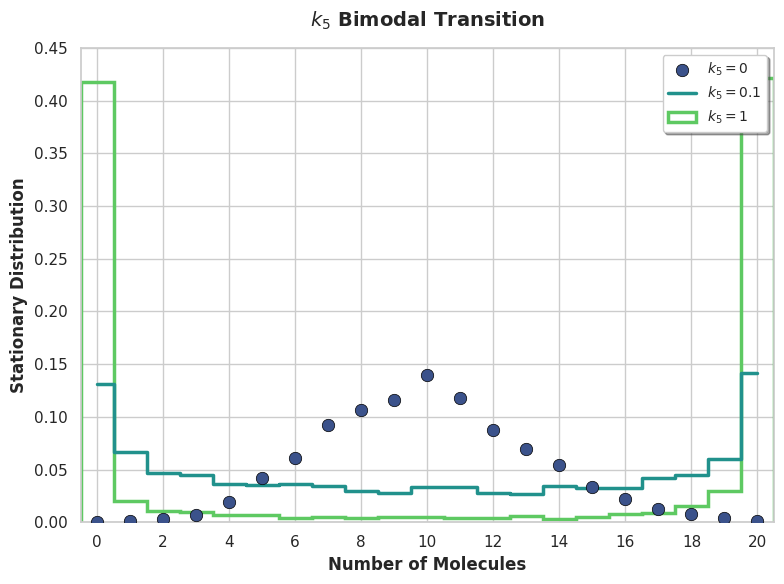

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import math
from numba import njit
import seaborn as sns # Import seaborn

t_max = 500.0
num_simulations = 5000

init_a = 0.0
init_b = 20.0
init_c = 0.0

@njit
def run_ssa_k5(k1, k2_v, k3_v, k4_v, k5_v, init_a, init_b, init_c, t_max):
    a = init_a
    b = init_b
    c = init_c
    t = 0.0

    while t < t_max:
        a1 = k1 * a
        a2 = k2_v * b * c
        a3 = k3_v
        a4 = k4_v * b * c
        a5_1 = k5_v * a * b
        a5_2 = k5_v * a * b

        a0 = a1 + a2 + a3 + a4 + a5_1 + a5_2
        if a0 == 0:
            break

        r1 = np.random.random()
        tau = (1.0 / a0) * math.log(1.0 / r1)
        t += tau

        r2 = np.random.random() * a0
        if r2 <= a1:
            a -= 1.0
            b += 1.0
        elif r2 <= (a1 + a2):
            b -= 1.0
            a += 1.0
        elif r2 <= (a1 + a2 + a3):
            c += 1.0
        elif r2 <= (a1 + a2 + a3 + a4):
            c -= 1.0
        elif r2 <= (a1 + a2 + a3 + a4 + a5_1):
            a += 1.0
            b -= 1.0
        else:
            a -= 1.0
            b += 1.0

    return a

def simulate_distribution_k5(k5_val):
    k1, k2_v, k3_v, k4_v = 0.1, 1.0, 100.0, 100.0
    results = np.zeros(num_simulations)
    for i in range(num_simulations):
        results[i] = run_ssa_k5(k1, k2_v, k3_v, k4_v, k5_val, init_a, init_b, init_c, t_max)
    return results

data_k5_0 = simulate_distribution_k5(0.0)
data_k5_01 = simulate_distribution_k5(0.1)
data_k5_1 = simulate_distribution_k5(1.0)

# Apply seaborn style
sns.set_theme(style="whitegrid") # Set a professional seaborn style

# Plotting Layout (a)
plt.figure(figsize=(8, 6), dpi=100) # Increase figure size and dpi for better resolution
bins = np.arange(-0.5, 21.5, 1)
bin_centers = np.arange(0, 21, 1)

# Get colors from the 'viridis' palette
viridis_colors = sns.color_palette("viridis", 3)

counts_0, _ = np.histogram(data_k5_0, bins=bins, density=True)
plt.scatter(bin_centers, counts_0, color=viridis_colors[0], label='$k_5 = 0$', zorder=3, s=80, edgecolors='black', linewidth=0.5) # Add edgecolors and size for scatter points

counts_01, _ = np.histogram(data_k5_01, bins=bins, density=True)
plt.step(bin_centers, counts_01, where='mid', color=viridis_colors[1], linewidth=2.5, label='$k_5 = 0.1$', zorder=2) # Increase linewidth

plt.hist(data_k5_1, bins=bins, density=True, histtype='step', color=viridis_colors[2], linewidth=2.5, label='$k_5 = 1$', zorder=1) # Increase linewidth

plt.xlim(-0.5, 20.5)
plt.xticks(np.arange(0, 21, 2))
plt.ylim(0, 0.45)
plt.xlabel('Number of Molecules', fontsize=12, fontweight='bold') # Enhance labels
plt.ylabel('Stationary Distribution', fontsize=12, fontweight='bold') # Enhance labels
plt.title('$k_5$ Bimodal Transition', fontsize=14, fontweight='bold', pad=15) # Enhance title
plt.legend(loc='upper right', fontsize=10, frameon=True, facecolor='white', shadow=True) # Add shadow to legend
plt.tight_layout()
plt.show()

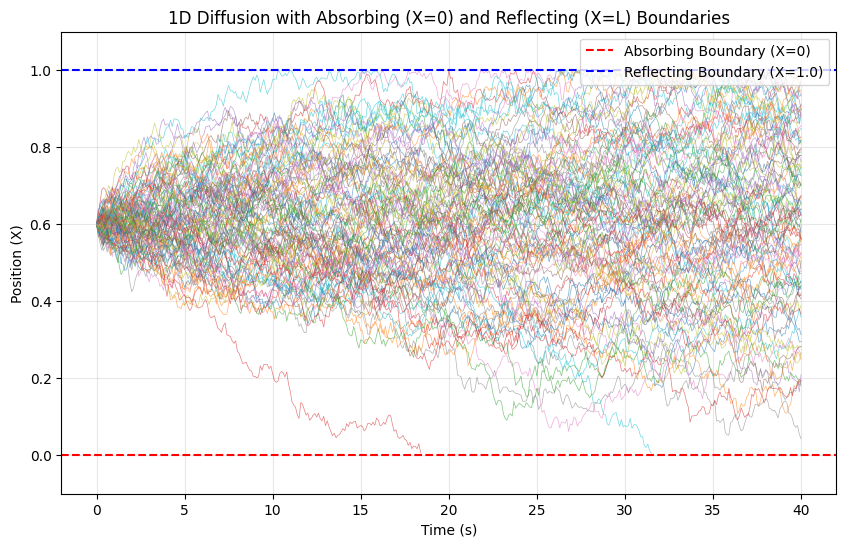

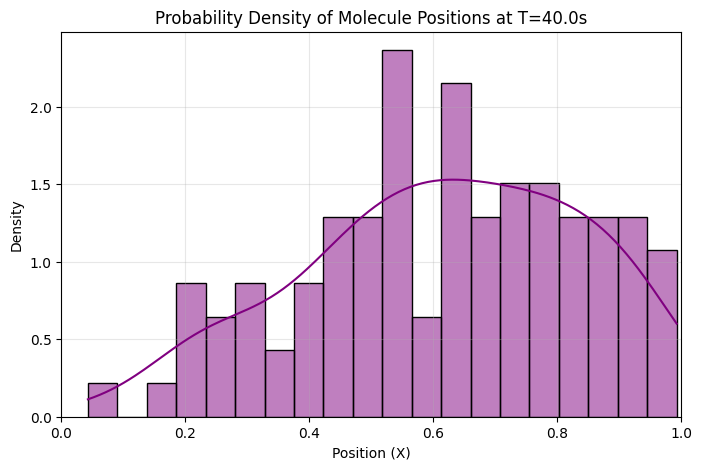

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Parameters ---
D = 10e-4
dt = 0.1
T = 40.0
num_steps = int(T / dt)
num_paths = 100
X_init = 0.6
L = 1.0  # Added Upper Reflecting Boundary

def simulate_vectorized():
    # Rows: paths, Columns: time steps
    trajectories = np.full((num_paths, num_steps + 1), np.nan)
    x = np.full(num_paths, X_init)
    trajectories[:, 0] = x

    # Active mask to track trajectories that haven't been absorbed at X=0
    active = np.ones(num_paths, dtype=bool)

    for t in range(1, num_steps + 1):
        if not np.any(active):
            break

        # (a13) Generate a normally distributed random number xi
        xi = np.random.normal(0, 1, num_paths)

        # (b13) Compute the tentative position of the molecule
        x_new = x + np.sqrt(2 * D * dt) * xi

        # --- Lower Boundary Logic (Absorbing at X=0) ---
        crossed_zero = x_new < 0

        # (d13) Check Brownian bridge probability for hidden hit
        p_hit = np.exp(-(x * x_new) / (D * dt))
        rand_draw = np.random.rand(num_paths)
        hidden_hit = (x_new >= 0) & (x_new <= L) & (rand_draw < p_hit)

        # Determine newly absorbed particles
        newly_absorbed = active & (crossed_zero | hidden_hit)
        active = active & ~newly_absorbed

        # --- Upper Boundary Logic (Reflecting at X=L) ---
        overshot_L = x_new > L
        reflected_position = 2 * L - x - np.sqrt(2 * D * dt) * xi
        x_new = np.where(overshot_L, reflected_position, x_new)

        # --- Finalize Positions ---
        x = np.where(active, x_new, x)
        trajectories[:, t] = np.where(active, x, np.nan)

    return trajectories

# --- Run Simulation ---
trajectories = simulate_vectorized()
time_grid = np.linspace(0, T, num_steps + 1)

# --- Plot 1: Trajectories ---
plt.figure(figsize=(10, 6))
plt.plot(time_grid, trajectories.T, lw=0.5, alpha=0.6)
plt.axhline(0, color='red', linestyle='--', label='Absorbing Boundary (X=0)')
plt.axhline(L, color='blue', linestyle='--', label=f'Reflecting Boundary (X={L})')
plt.title("1D Diffusion with Absorbing (X=0) and Reflecting (X=L) Boundaries")
plt.xlabel("Time (s)")
plt.ylabel("Position (X)")
plt.ylim(-0.1, L + 0.1)
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.show()

# --- Plot 2: Probability Density at Final Time ---
# Extract the final positions (all paths, last time step), filtering out NaNs
final_data = trajectories[:, -1]
final_data = final_data[~np.isnan(final_data)]

plt.figure(figsize=(8, 5))
sns.histplot(final_data, stat="density", kde=True, bins=20, color='purple')
plt.title(f"Probability Density of Molecule Positions at T={T}s")
plt.xlabel("Position (X)")
plt.ylabel("Density")
plt.xlim(0, L)
plt.grid(True, alpha=0.3)
plt.show()